# Query-Plan Experiment Notebook

### Problem
A developer adds an index because a query "feels slow", without knowing the workload or what the index costs on writes. I build a repeatable experiment: same fake data, same queries, several index candidates, and a report with plans, repeated timings, results checks and write cost.

### What I build
1. Fake `customers` and `orders` tables (fixed seed, skewed on purpose: a few heavy customers, one dominant status)
2. 5 representative queries (filter, pagination, join + group by, a low-selectivity filter and a deliberately terrible query)
3. 5 index candidates: none, `customer_id`, `(status, created_at)`, `status` only, `(created_at, customer_id)`
4. For every candidate: same result check (hash), query plan, 9 timed runs (a warm-up run is kept separate, candidates take turns in a rotating order), index size and write cost
5. A report file (JSON) with versions, row counts and measurement conditions
6. Acceptance tests. A timed-out query stays visible in the results

### How to run
Run all cells. About 1 to 2 minutes. Needs: pandas, numpy, matplotlib. The timings depend on the machine, so read them as relative, not absolute.

In [1]:
!pip install -q pandas numpy matplotlib

## Step 1: Imports and settings

In [2]:
import json
import time
import sqlite3
import hashlib
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
N_CUSTOMERS = 5000
N_ORDERS = 200000
RUNS = 9
WRITE_REPS = 5
TIMEOUT_SECONDS = 0.5
np.random.seed(SEED)
print("sqlite version:", sqlite3.sqlite_version)

sqlite version: 3.45.1


## Step 2: Make skewed fake data
- customer weights are `1 / rank`, so customer 1 has the most orders and most customers have few
- status: 85% delivered, 8% shipped, 5% pending, 2% cancelled (so `status` alone is a weak filter, but `pending` is rare)
- `created_at` is a date text across 365 days

In [3]:
regions = ["north", "south", "east", "west", "central"]
customers = [(i + 1, "customer_" + str(i + 1), regions[i % 5]) for i in range(N_CUSTOMERS)]

weights = 1.0 / np.arange(1, N_CUSTOMERS + 1)
weights = weights / weights.sum()
cust_ids = np.random.choice(np.arange(1, N_CUSTOMERS + 1), size=N_ORDERS, p=weights)
status = np.random.choice(["delivered", "shipped", "pending", "cancelled"], size=N_ORDERS, p=[0.85, 0.08, 0.05, 0.02])
days = np.random.randint(0, 365, size=N_ORDERS)
amounts = np.round(np.random.lognormal(4, 0.8, size=N_ORDERS), 2)

base_date = np.datetime64("2025-11-01")
dates = [str(base_date + int(d)) for d in days]
orders = [(i + 1, int(cust_ids[i]), str(status[i]), dates[i], float(amounts[i])) for i in range(N_ORDERS)]

print("customers:", len(customers), "| orders:", len(orders))
print("orders for customer 3 (heavy):", int((cust_ids == 3).sum()), "| for customer 4000 (light):", int((cust_ids == 4000).sum()))
print(pd.Series(status).value_counts(normalize=True).round(3).to_dict())

customers: 5000 | orders: 200000
orders for customer 3 (heavy): 7344 | for customer 4000 (light): 5
{'delivered': 0.85, 'shipped': 0.08, 'pending': 0.05, 'cancelled': 0.02}


## Step 3: The base database and the candidates
`base` has the tables and the data but no extra index. Every candidate is a copy of `base` plus ONE index set, so the only thing that changes is the index.

In [4]:
base = sqlite3.connect(":memory:")
base.execute("create table customers (customer_id integer primary key, name text, region text)")
base.execute("create table orders (order_id integer primary key, customer_id integer, status text, created_at text, amount real)")
base.executemany("insert into customers values (?,?,?)", customers)
base.executemany("insert into orders values (?,?,?,?,?)", orders)
base.commit()
base.execute("analyze")

CANDIDATES = {
    "none": [],
    "idx_customer": ["create index idx_orders_customer on orders (customer_id)"],
    "idx_status_created": ["create index idx_orders_status_created on orders (status, created_at)"],
    "idx_status_only": ["create index idx_orders_status on orders (status)"],
    "idx_created_cust": ["create index idx_orders_created_cust on orders (created_at, customer_id)"],
}


def size_bytes(con):
    return con.execute("pragma page_count").fetchone()[0] * con.execute("pragma page_size").fetchone()[0]


dbs = {}
for name, stmts in CANDIDATES.items():
    c = sqlite3.connect(":memory:")
    base.backup(c)
    for s in stmts:
        c.execute(s)
    c.execute("analyze")
    c.commit()
    dbs[name] = c

sizes = {name: size_bytes(c) for name, c in dbs.items()}
extra_mb = {name: round((sizes[name] - sizes["none"]) / 1024 / 1024, 2) for name in sizes}
print("index size added (MB):", extra_mb)

index size added (MB): {'none': 0.0, 'idx_customer': 1.95, 'idx_status_created': 5.5, 'idx_status_only': 3.37, 'idx_created_cust': 4.06}


## Step 4: Representative queries (with the expected result, not only a latency target)
| id | what it is | why it matters |
|---|---|---|
| Q1a | orders of heavy customer 3 | filter on a very common key |
| Q1b | orders of light customer 4000 | same filter, rare key |
| Q2 | pending orders, newest first, page 6 (limit 20 offset 100) | filter + order + pagination |
| Q3 | revenue by region since 2026-06-01 (join + group by) | join and aggregation |
| Q4 | count of delivered orders | low-selectivity filter (85% of rows), tests if an index really helps here |
| Q5 | a deliberately terrible self-join | shows how a timeout is reported |

In [5]:
QUERIES = {
    "Q1a heavy customer": ("select count(*), round(sum(amount), 2) from orders where customer_id = 3", []),
    "Q1b light customer": ("select count(*), round(sum(amount), 2) from orders where customer_id = 4000", []),
    "Q2 pending page 6": ("select order_id, created_at, amount from orders where status = 'pending' order by created_at desc, order_id desc limit 20 offset 100", []),
    "Q3 revenue by region": ("select c.region, count(*), round(sum(o.amount), 2) from orders o join customers c on c.customer_id = o.customer_id where o.created_at >= '2026-06-01' group by c.region order by c.region", []),
    "Q4 delivered count": ("select count(*) from orders where status = 'delivered'", []),
    "Q5 bad self-join": ("select count(*) from orders a, orders b where a.amount + b.amount = 12345.67", []),
}
print(list(QUERIES.keys()))

['Q1a heavy customer', 'Q1b light customer', 'Q2 pending page 6', 'Q3 revenue by region', 'Q4 delivered count', 'Q5 bad self-join']


## Step 5: Query plans (what SQLite says it will do)
A plan is a prediction, not a measurement. I save one plan per query and candidate.

In [6]:
plans = {}
for cname, con in dbs.items():
    for qname, (sql, params) in QUERIES.items():
        rows = con.execute("explain query plan " + sql, params).fetchall()
        plans[(cname, qname)] = " | ".join(r[3] for r in rows)

for qname in ["Q1a heavy customer", "Q2 pending page 6", "Q3 revenue by region", "Q4 delivered count"]:
    print(qname)
    for cname in CANDIDATES:
        print("   ", cname.ljust(20), plans[(cname, qname)])
    print()

Q1a heavy customer
    none                 SCAN orders
    idx_customer         SEARCH orders USING INDEX idx_orders_customer (customer_id=?)
    idx_status_created   SCAN orders
    idx_status_only      SCAN orders
    idx_created_cust     SEARCH orders USING INDEX idx_orders_created_cust (ANY(created_at) AND customer_id=?)

Q2 pending page 6
    none                 SCAN orders | USE TEMP B-TREE FOR ORDER BY
    idx_customer         SCAN orders | USE TEMP B-TREE FOR ORDER BY
    idx_status_created   SEARCH orders USING INDEX idx_orders_status_created (status=?)
    idx_status_only      SEARCH orders USING INDEX idx_orders_status (status=?) | USE TEMP B-TREE FOR ORDER BY
    idx_created_cust     SCAN orders | USE TEMP B-TREE FOR ORDER BY

Q3 revenue by region
    none                 SCAN o | SEARCH c USING INTEGER PRIMARY KEY (rowid=?) | USE TEMP B-TREE FOR GROUP BY
    idx_customer         SCAN c | SEARCH o USING INDEX idx_orders_customer (customer_id=?) | USE TEMP B-TREE FOR GROUP

## Step 6: Run the experiment
- Every query gets 1 warm-up run per candidate (kept separate, not in the median) and then 9 timed runs
- The candidates **take turns** in a rotating order inside every round, so a slow moment on the machine does not hit only one candidate
- A hash of the result rows must be the same for every candidate
- Q5 has a time limit of 0.5 seconds. If it hits the limit the run is stored as `timeout` with the limit as its time, and it stays in the table
- Each row also says if the plan is the **same as the plan without an index**. Same plan + different time = noise, and this is used below to measure the noise floor

In [7]:
def run_once(con, sql, params, limit=None):
    start = time.perf_counter()
    if limit is not None:
        deadline = start + limit
        con.set_progress_handler(lambda: 1 if time.perf_counter() > deadline else 0, 10000)
    try:
        rows = con.execute(sql, params).fetchall()
        status_ = "ok"
    except sqlite3.OperationalError as e:
        rows = None
        status_ = "timeout" if "interrupt" in str(e).lower() else "error"
    finally:
        if limit is not None:
            con.set_progress_handler(None, 0)
    ms = (time.perf_counter() - start) * 1000
    return rows, status_, ms


def row_hash(rows):
    return hashlib.sha256(repr(rows).encode()).hexdigest()[:10]


results = []
names = list(dbs.keys())
for qname, (sql, params) in QUERIES.items():
    is_bad = qname.startswith("Q5")
    n_runs = 3 if is_bad else RUNS
    times = {c: [] for c in names}
    statuses = {c: [] for c in names}
    hashes = {c: set() for c in names}
    warm = {c: 0.0 for c in names}
    if not is_bad:
        for c in names:
            rows, st, ms = run_once(dbs[c], sql, params)
            warm[c] = ms
    for r in range(n_runs):
        k = r % len(names)
        order = names[k:] + names[:k]
        for c in order:
            rows, st, ms = run_once(dbs[c], sql, params, TIMEOUT_SECONDS if is_bad else None)
            times[c].append(ms)
            statuses[c].append(st)
            if rows is not None:
                hashes[c].add(row_hash(rows))
    for c in names:
        t = times[c]
        results.append({"candidate": c, "query": qname, "runs": n_runs, "warmup_ms": round(warm[c], 2),
                        "median_ms": round(statistics.median(t), 2), "min_ms": round(min(t), 2), "max_ms": round(max(t), 2),
                        "timeouts": statuses[c].count("timeout"), "errors": statuses[c].count("error"),
                        "plan_same_as_none": plans[(c, qname)] == plans[("none", qname)],
                        "result_hash": ",".join(sorted(hashes[c])) if hashes[c] else "none"})

res = pd.DataFrame(results)
pivot = res.pivot(index="query", columns="candidate", values="median_ms")[list(CANDIDATES.keys())]
print("MEDIAN ms over all runs:")
print(pivot.to_string())
print()
print("timeouts (never removed from the table):")
print(res[res["timeouts"] > 0][["candidate", "query", "runs", "timeouts", "median_ms"]].to_string(index=False))

MEDIAN ms over all runs:
candidate               none  idx_customer  idx_status_created  idx_status_only  idx_created_cust
query                                                                                            
Q1a heavy customer     10.26          3.54                9.38             9.20              5.90
Q1b light customer      8.62          0.02                8.59             8.57              0.69
Q2 pending page 6      10.71         10.63                0.07             4.99             10.81
Q3 revenue by region  109.32        318.37              180.11           124.85            185.54
Q4 delivered count     17.98         18.34               11.26            11.10             18.22
Q5 bad self-join      500.10        500.11              500.11           500.10            500.06

timeouts (never removed from the table):
         candidate            query  runs  timeouts  median_ms
              none Q5 bad self-join     3         3     500.10
      idx_customer Q5 b

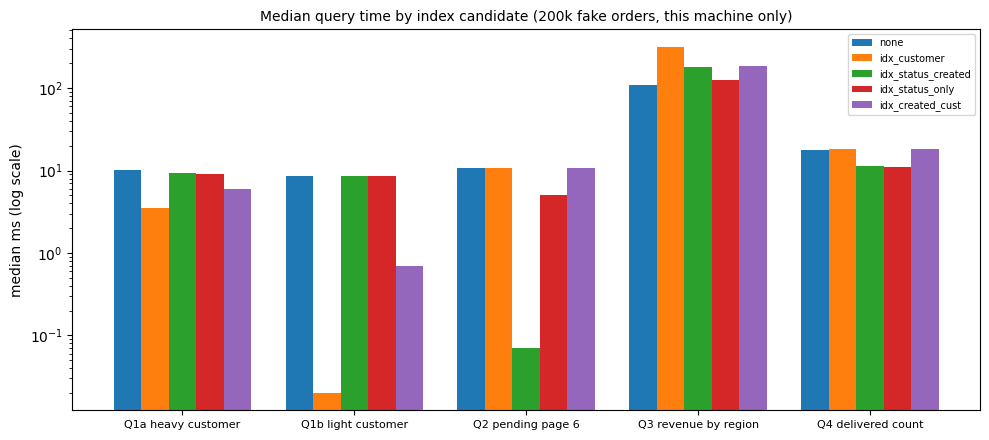

In [8]:
ok_q = [q for q in QUERIES if not q.startswith("Q5")]
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.16
for i, cname in enumerate(CANDIDATES):
    vals = [pivot.loc[q, cname] for q in ok_q]
    ax.bar([k + i * width for k in range(len(ok_q))], vals, width, label=cname)
ax.set_xticks([k + 2 * width for k in range(len(ok_q))])
ax.set_xticklabels(ok_q, fontsize=8)
ax.set_yscale("log")
ax.set_ylabel("median ms (log scale)")
ax.set_title("Median query time by index candidate (200k fake orders, this machine only)", fontsize=10)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("query_times.png")
plt.show()

## Step 6b: How noisy is this machine? Then, what is a real effect?
If two candidates have the **same plan** for a query, any time difference between them is noise. So the biggest such gap is the noise floor of this run. A speed change is only called real when the plan changed **and** the change is bigger than the noise floor of that query (never below x1.3).

In [9]:
ok_q = [q for q in QUERIES if not q.startswith("Q5")]
noise_rows = []
for q in ok_q:
    part = res[(res["query"] == q) & (res["plan_same_as_none"])]
    if len(part) > 1:
        noise_rows.append({"query": q, "same_plan_candidates": len(part), "slowest_vs_fastest": round(part["median_ms"].max() / max(part["median_ms"].min(), 0.01), 2)})
noise_df = pd.DataFrame(noise_rows)
print(noise_df.to_string(index=False))
NOISE_FLOOR = max(1.3, float(noise_df["slowest_vs_fastest"].max())) if len(noise_df) > 0 else 1.3
floors = {}
for r in noise_df.itertuples():
    floors[r.query] = max(1.3, r.slowest_vs_fastest)
print("noise floor per query:", {k: round(v, 2) for k, v in floors.items()})
print("biggest noise floor in this run: x" + str(round(NOISE_FLOOR, 2)))

verdict_rows = []
for q in ok_q:
    none_ms = float(res[(res["query"] == q) & (res["candidate"] == "none")]["median_ms"].iloc[0])
    for c in CANDIDATES:
        if c == "none":
            continue
        row = res[(res["query"] == q) & (res["candidate"] == c)].iloc[0]
        ratio = none_ms / max(row["median_ms"], 0.01)
        floor_q = floors.get(q, NOISE_FLOOR)
        if row["plan_same_as_none"]:
            v = "same plan (differences are noise)"
        elif ratio >= floor_q:
            v = "FASTER x" + str(round(ratio, 1))
        elif ratio <= 1 / floor_q:
            v = "SLOWER x" + str(round(1 / ratio, 1))
        else:
            v = "new plan, change within noise"
        verdict_rows.append({"query": q, "candidate": c, "median_ms": row["median_ms"], "none_ms": none_ms, "verdict": v})
verdict_df = pd.DataFrame(verdict_rows)
print()
print(verdict_df[verdict_df["verdict"].str.contains("FASTER|SLOWER")].to_string(index=False))

               query  same_plan_candidates  slowest_vs_fastest
  Q1a heavy customer                     3                1.12
  Q1b light customer                     3                1.01
   Q2 pending page 6                     3                1.02
Q3 revenue by region                     2                1.14
  Q4 delivered count                     3                1.02
noise floor per query: {'Q1a heavy customer': 1.3, 'Q1b light customer': 1.3, 'Q2 pending page 6': 1.3, 'Q3 revenue by region': 1.3, 'Q4 delivered count': 1.3}
biggest noise floor in this run: x1.3

               query          candidate  median_ms  none_ms       verdict
  Q1a heavy customer       idx_customer       3.54    10.26   FASTER x2.9
  Q1a heavy customer   idx_created_cust       5.90    10.26   FASTER x1.7
  Q1b light customer       idx_customer       0.02     8.62 FASTER x431.0
  Q1b light customer   idx_created_cust       0.69     8.62  FASTER x12.5
   Q2 pending page 6 idx_status_created       0.07   

## Step 7: Is the benefit worth the write cost?
For every candidate, on a fresh copy of `base`: insert 20,000 new orders and update the status of 5,000 orders. This is repeated 5 times, the candidates take turns in a rotating order, and one throw-away warm-up round is done first. A candidate is only called slower or faster than `none` when its min to max range does **not** overlap the range of `none` AND the median changed by more than the noise floor. Extra index size comes from Step 3.

In [10]:
new_orders = [(N_ORDERS + 1 + i, int(np.random.choice([3, 10, 500, 4000])), "pending", "2026-10-30", 99.5) for i in range(20000)]


def write_test(cname):
    c = sqlite3.connect(":memory:")
    base.backup(c)
    for stmt in CANDIDATES[cname]:
        c.execute(stmt)
    c.commit()
    t0 = time.perf_counter()
    c.executemany("insert into orders values (?,?,?,?,?)", new_orders)
    c.commit()
    ins = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    c.execute("update orders set status = 'shipped' where order_id between 1 and 5000")
    c.commit()
    upd = (time.perf_counter() - t0) * 1000
    c.close()
    return ins, upd


cnames = list(CANDIDATES.keys())
for c in cnames:
    write_test(c)

ins_times = {c: [] for c in cnames}
upd_times = {c: [] for c in cnames}
for rep in range(WRITE_REPS):
    k = rep % len(cnames)
    for c in cnames[k:] + cnames[:k]:
        i_ms, u_ms = write_test(c)
        ins_times[c].append(i_ms)
        upd_times[c].append(u_ms)


def verdict(list_c, list_none):
    ratio = statistics.median(list_c) / max(statistics.median(list_none), 0.01)
    if min(list_c) > max(list_none) and ratio >= NOISE_FLOOR:
        return "slower x" + str(round(ratio, 1))
    if max(list_c) < min(list_none) and ratio <= 1 / NOISE_FLOOR:
        return "faster x" + str(round(1 / ratio, 1))
    return "unclear (inside noise)"


write_rows = []
for c in cnames:
    write_rows.append({"candidate": c,
                       "insert_20k_median_ms": round(statistics.median(ins_times[c]), 1),
                       "insert_range": str(round(min(ins_times[c]), 1)) + "-" + str(round(max(ins_times[c]), 1)),
                       "insert_vs_none": "-" if c == "none" else verdict(ins_times[c], ins_times["none"]),
                       "update_5k_median_ms": round(statistics.median(upd_times[c]), 1),
                       "update_range": str(round(min(upd_times[c]), 1)) + "-" + str(round(max(upd_times[c]), 1)),
                       "update_vs_none": "-" if c == "none" else verdict(upd_times[c], upd_times["none"]),
                       "extra_index_mb": extra_mb[c]})
write_df = pd.DataFrame(write_rows)
print(write_df.to_string(index=False))

         candidate  insert_20k_median_ms insert_range         insert_vs_none  update_5k_median_ms update_range         update_vs_none  extra_index_mb
              none                  19.5    19.0-32.4                      -                  1.4      1.4-2.3                      -            0.00
      idx_customer                  32.0    31.4-35.3 unclear (inside noise)                  1.4      1.3-1.5 unclear (inside noise)            1.95
idx_status_created                  54.1    37.1-64.9            slower x2.8                 13.5    12.4-23.1            slower x9.4            5.50
   idx_status_only                  33.8    33.4-56.1            slower x1.7                  6.7     6.6-13.1            slower x4.7            3.37
  idx_created_cust                  41.1    36.7-61.8            slower x2.1                  1.4      1.3-2.3 unclear (inside noise)            4.06


## Step 8: Acceptance tests

In [11]:
# test 1: every candidate returns the same result for every query that finished
all_same = True
for qname in QUERIES:
    if qname.startswith("Q5"):
        continue
    hs = set(res[res["query"] == qname]["result_hash"])
    if len(hs) != 1:
        all_same = False
        print("   result differs for", qname, hs)
print("TEST 1 identical results across all candidates:", "PASS" if all_same else "FAIL")

# test 2: the report records plan, versions, row counts, conditions
report = {"sqlite_version": sqlite3.sqlite_version, "seed": SEED, "rows": {"customers": N_CUSTOMERS, "orders": N_ORDERS},
          "runs_per_query": RUNS, "timeout_seconds": TIMEOUT_SECONDS,
          "conditions": "single in-memory SQLite db per candidate, same process, page cache warm after first run, machine not controlled",
          "extra_index_mb": extra_mb, "noise_floor": round(NOISE_FLOOR, 2),
          "plans": {c + " | " + q: p for (c, q), p in plans.items()},
          "timings": res.to_dict(orient="records"), "write_cost": write_df.to_dict(orient="records")}
with open("query_plan_report.json", "w") as f:
    json.dump(report, f, indent=1)
need = ["sqlite_version", "rows", "plans", "conditions", "timings"]
print("TEST 2 report has", need, ":", "PASS" if all(k in report for k in need) else "FAIL", "-> saved query_plan_report.json")

# test 3: the timeout is visible, not removed
q5 = res[res["query"].str.startswith("Q5")]
print("TEST 3 Q5 timeouts recorded:", int(q5["timeouts"].sum()), "of", int(q5["runs"].sum()), "runs ->", "PASS" if int(q5["timeouts"].sum()) > 0 else "FAIL")

TEST 1 identical results across all candidates: PASS
TEST 2 report has ['sqlite_version', 'rows', 'plans', 'conditions', 'timings'] : PASS -> saved query_plan_report.json
TEST 3 Q5 timeouts recorded: 15 of 15 runs -> PASS


## Step 9: Key insights

In [12]:
print("1) Real effects (plan changed AND bigger than the noise floor of that query):")
real = verdict_df[verdict_df["verdict"].str.contains("FASTER|SLOWER")]
for r in real.itertuples():
    print("   -", r.query, "with", r.candidate, "->", r.verdict, "(" + str(r.none_ms) + " ms -> " + str(r.median_ms) + " ms)")
if len(real) == 0:
    print("   none")

print()
print("2) Plan changed but the speed change is inside the noise:")
unclear = verdict_df[verdict_df["verdict"] == "new plan, change within noise"]
for r in unclear.itertuples():
    print("   -", r.query, "with", r.candidate)
if len(unclear) == 0:
    print("   none")

print()
print("3) Write cost (a change is only called real when the ranges do not overlap and it is bigger than the noise floor):")
for r in write_df[write_df["candidate"] != "none"].itertuples():
    print("   -", r.candidate, "| insert:", r.insert_vs_none, "| update:", r.update_vs_none, "| extra size:", r.extra_index_mb, "MB")

print()
print("4) Timed-out queries stay in the report:", int(res["timeouts"].sum()), "timeouts in Q5.")
print("5) These are numbers for fake data on one machine. They are evidence for this workload, not a rule for every database.")

1) Real effects (plan changed AND bigger than the noise floor of that query):
   - Q1a heavy customer with idx_customer -> FASTER x2.9 (10.26 ms -> 3.54 ms)
   - Q1a heavy customer with idx_created_cust -> FASTER x1.7 (10.26 ms -> 5.9 ms)
   - Q1b light customer with idx_customer -> FASTER x431.0 (8.62 ms -> 0.02 ms)
   - Q1b light customer with idx_created_cust -> FASTER x12.5 (8.62 ms -> 0.69 ms)
   - Q2 pending page 6 with idx_status_created -> FASTER x153.0 (10.71 ms -> 0.07 ms)
   - Q2 pending page 6 with idx_status_only -> FASTER x2.1 (10.71 ms -> 4.99 ms)
   - Q3 revenue by region with idx_customer -> SLOWER x2.9 (109.32 ms -> 318.37 ms)
   - Q3 revenue by region with idx_status_created -> SLOWER x1.6 (109.32 ms -> 180.11 ms)
   - Q3 revenue by region with idx_created_cust -> SLOWER x1.7 (109.32 ms -> 185.54 ms)
   - Q4 delivered count with idx_status_created -> FASTER x1.6 (17.98 ms -> 11.26 ms)
   - Q4 delivered count with idx_status_only -> FASTER x1.6 (17.98 ms -> 11.1 ms)



---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info

